C:\Users\DELL\AppData\Local\Temp\ipykernel_1884\3574927797.py:25: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

C:\Users\DELL\AppData\Local\Temp\ipykernel_1884\3574927797.py:36: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



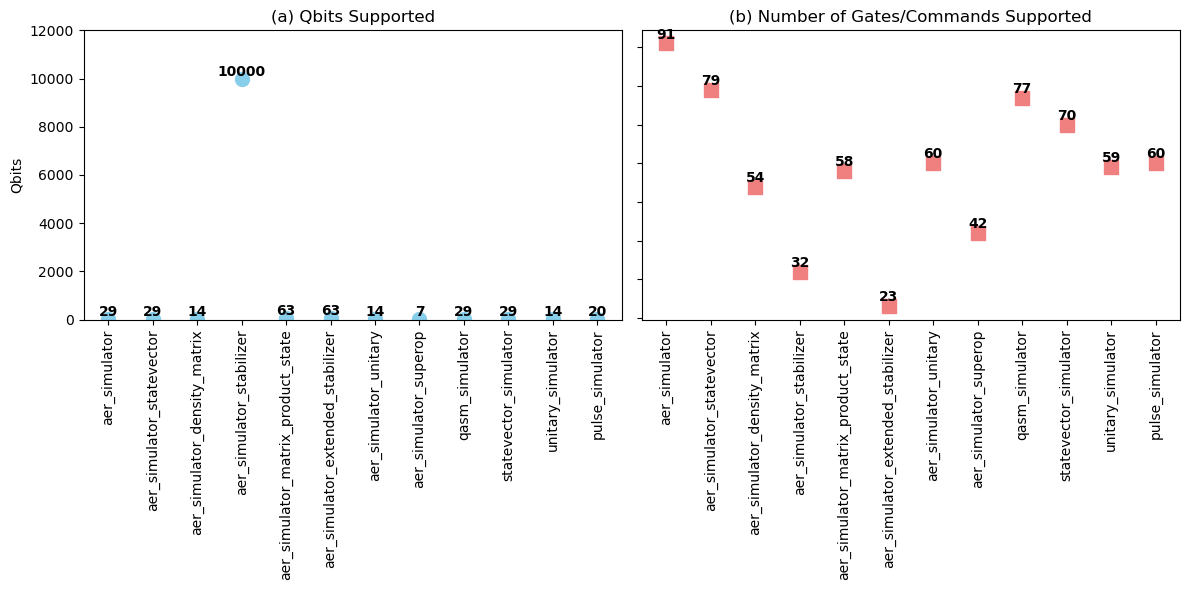

In [62]:
import matplotlib.pyplot as plt

# Data for plotting
simulators = [
    "aer_simulator", "aer_simulator_statevector", "aer_simulator_density_matrix",
    "aer_simulator_stabilizer", "aer_simulator_matrix_product_state", 
    "aer_simulator_extended_stabilizer", "aer_simulator_unitary", 
    "aer_simulator_superop", "qasm_simulator", "statevector_simulator", 
    "unitary_simulator", "pulse_simulator"
]
qbits = [29, 29, 14, 10000, 63, 63, 14, 7, 29, 29, 14, 20]
max_shots = [1000000]*12
no_of_gates = [91, 79, 54, 32, 58, 23, 60, 42, 77, 70, 59, 60]

# Create figure for both graphs
fig = plt.figure(figsize=(12, 6))

# First subplot for Qbits (using circles)
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(simulators, qbits, color='skyblue', marker='o', s=100)  # Circle markers
ax1.set_title("(a) Qbits Supported")
for i, v in enumerate(qbits):
    ax1.text(i, v + 0.5, str(v), ha='center', va='bottom', color='black', fontweight='bold')
ax1.set_ylim(0, max(qbits) + 2000)
ax1.set_xticklabels(simulators, rotation=90)

# Add y-axis labels only to the first graph (ax1)
ax1.set_ylabel("Qbits")

# Second subplot for Number of Gates (using squares)
ax3 = fig.add_subplot(1, 2, 2)
ax3.scatter(simulators, no_of_gates, color='lightcoral', marker='s', s=100)  # Square markers
ax3.set_title("(b) Number of Gates/Commands Supported")
for i, v in enumerate(no_of_gates):
    ax3.text(i, v + 0.5, str(v), ha='center', va='bottom', color='black', fontweight='bold')
ax3.set_xticklabels(simulators, rotation=90)

# Remove y-axis labels for the second graph (ax3)
ax3.set_yticklabels([])

# Adjust layout for better spacing
plt.tight_layout()

# Save the figure
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\alliksitsimulators.png')

# Show the plot
plt.show()


In [1]:
pip install bibtexparser matplotlib pandas


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for bibtexparser: filename=bibtexparser-1.4.3-py3-none-any.whl size=43617 sha256=4f8f4ee10cdcdf5b5b6354ca13ea3982b579fa467538e5b9246c1eccc67d3421
  Stored in directory: c:\users\muroo\appdata\local\pip\cache\wheels\a6\24\17\03a15b5ba126a5362b73c9405afb7ff4518f83cc0b7310e620
Successfully built bibtexparser
Note: you may need to restart the kernel to use updated packages.


In [8]:
pip install seaborn

Note: you may need to restart the kernel to use updated packages.


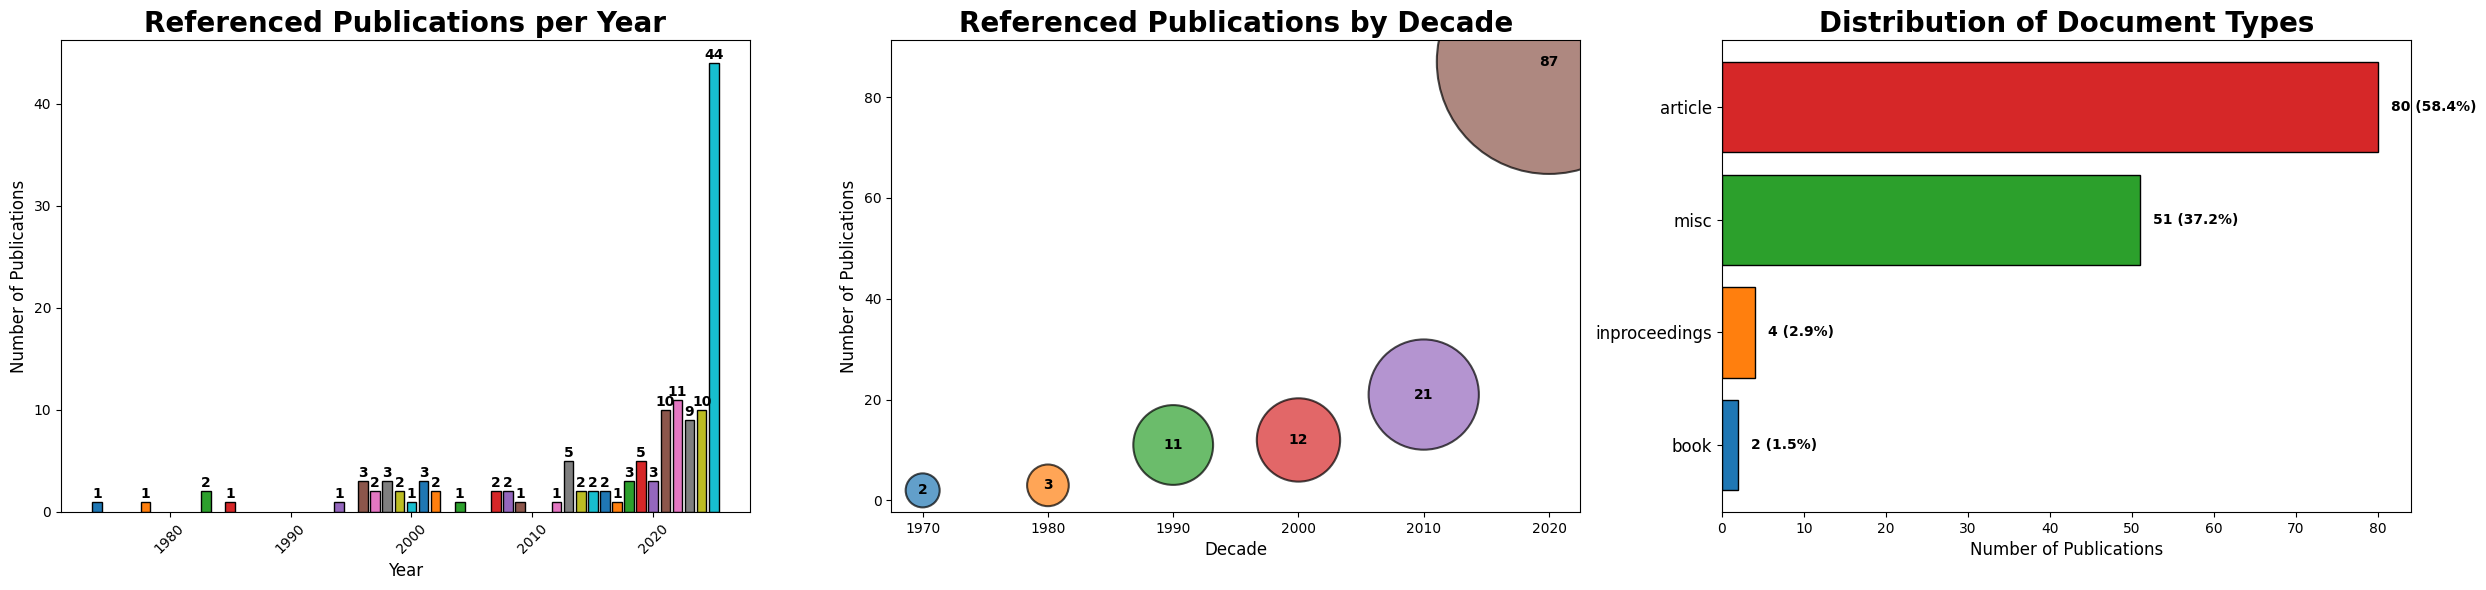

In [8]:
import bibtexparser
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Path to your BibTeX file (update if needed)
bib_file_path = r'D:\Journals\Quantumreviewpaper\Code\mybib.bib'

with open(bib_file_path, "r", encoding="utf-8") as bibtex_file:
    bib_database = bibtexparser.load(bibtex_file)

# Initialize lists to store extracted data
years = []
doc_types = []

for entry in bib_database.entries:
    year_str = entry.get('year', None)
    try:
        year = int(year_str)
    except (ValueError, TypeError):
        year = None
    years.append(year)
    doc_types.append(entry.get('ENTRYTYPE', 'Unknown'))

# Create a DataFrame from the extracted data
df = pd.DataFrame({'year': years, 'doc_type': doc_types})

# Filter entries with a valid year
df_year = df[df['year'].notnull()].copy()

# (a) Count publications per year
pubs_per_year = df_year['year'].value_counts().sort_index()

# (b) Count publications by decade
df_year['decade'] = df_year['year'].apply(lambda x: (x // 10) * 10)
pubs_by_decade = df_year['decade'].value_counts().sort_index()

# (c) Count document types
doc_type_counts = df['doc_type'].value_counts()

# ---------------------------
# Create Professional Subplots (1 row, 3 columns)
# ---------------------------
fig, axes = plt.subplots(1, 3, figsize=(25, 6))

# Define a colormap for distinct colors
cmap = plt.get_cmap('tab10')

# (a) Referenced Publications per Year (Bar Chart)
ax1 = axes[0]
colors_a = [cmap(i % 10) for i in range(len(pubs_per_year))]
bars = ax1.bar(pubs_per_year.index, pubs_per_year.values, color=colors_a, edgecolor='black')
ax1.set_title('Referenced Publications per Year', fontsize=20, fontweight='bold')
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Number of Publications', fontsize=12)
ax1.tick_params(axis='x', rotation=45)
# Annotate each bar with its count
for bar in bars:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.1, f'{int(height)}', 
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# (b) Referenced Publications by Decade (Bubble Chart)
ax2 = axes[1]
decades = pubs_by_decade.index.astype(int)
counts = pubs_by_decade.values
bubble_size_factor = 300
sizes = counts * bubble_size_factor
colors_b = [cmap(i % 10) for i in range(len(decades))]
scatter = ax2.scatter(decades, counts, s=sizes, color=colors_b, alpha=0.7,
                      edgecolors='black', linewidth=1.5)
ax2.set_title('Referenced Publications by Decade', fontsize=20, fontweight='bold')
ax2.set_xlabel('Decade', fontsize=12)
ax2.set_ylabel('Number of Publications', fontsize=12)
ax2.set_xticks(decades)
ax2.set_xticklabels(decades, fontsize=10)
# Annotate each bubble with its count
for x, y in zip(decades, counts):
    ax2.text(x, y, f'{int(y)}', ha='center', va='center', fontsize=10, fontweight='bold')

# (c) Distribution of Document Types (Horizontal Bar Chart)
ax3 = axes[2]
doc_type_counts = doc_type_counts.sort_values()
y_pos = np.arange(len(doc_type_counts))
colors_c = [cmap(i % 10) for i in range(len(doc_type_counts))]
bars_c = ax3.barh(y_pos, doc_type_counts.values, color=colors_c, edgecolor='black')
ax3.set_yticks(y_pos)
ax3.set_yticklabels(doc_type_counts.index, fontsize=12)
ax3.set_xlabel('Number of Publications', fontsize=12)
ax3.set_title('Distribution of Document Types', fontsize=20, fontweight='bold')

# Annotate each bar with count and percentage
total = doc_type_counts.sum()
max_val = doc_type_counts.max()
for i, v in enumerate(doc_type_counts.values):
    percentage = (v / total) * 100
    ax3.text(v + max_val * 0.02, i, f'{v} ({percentage:.1f}%)', color='black',
             va='center', fontsize=10, fontweight='bold')

# Adjust layout for better visibility
plt.tight_layout()
plt.show()




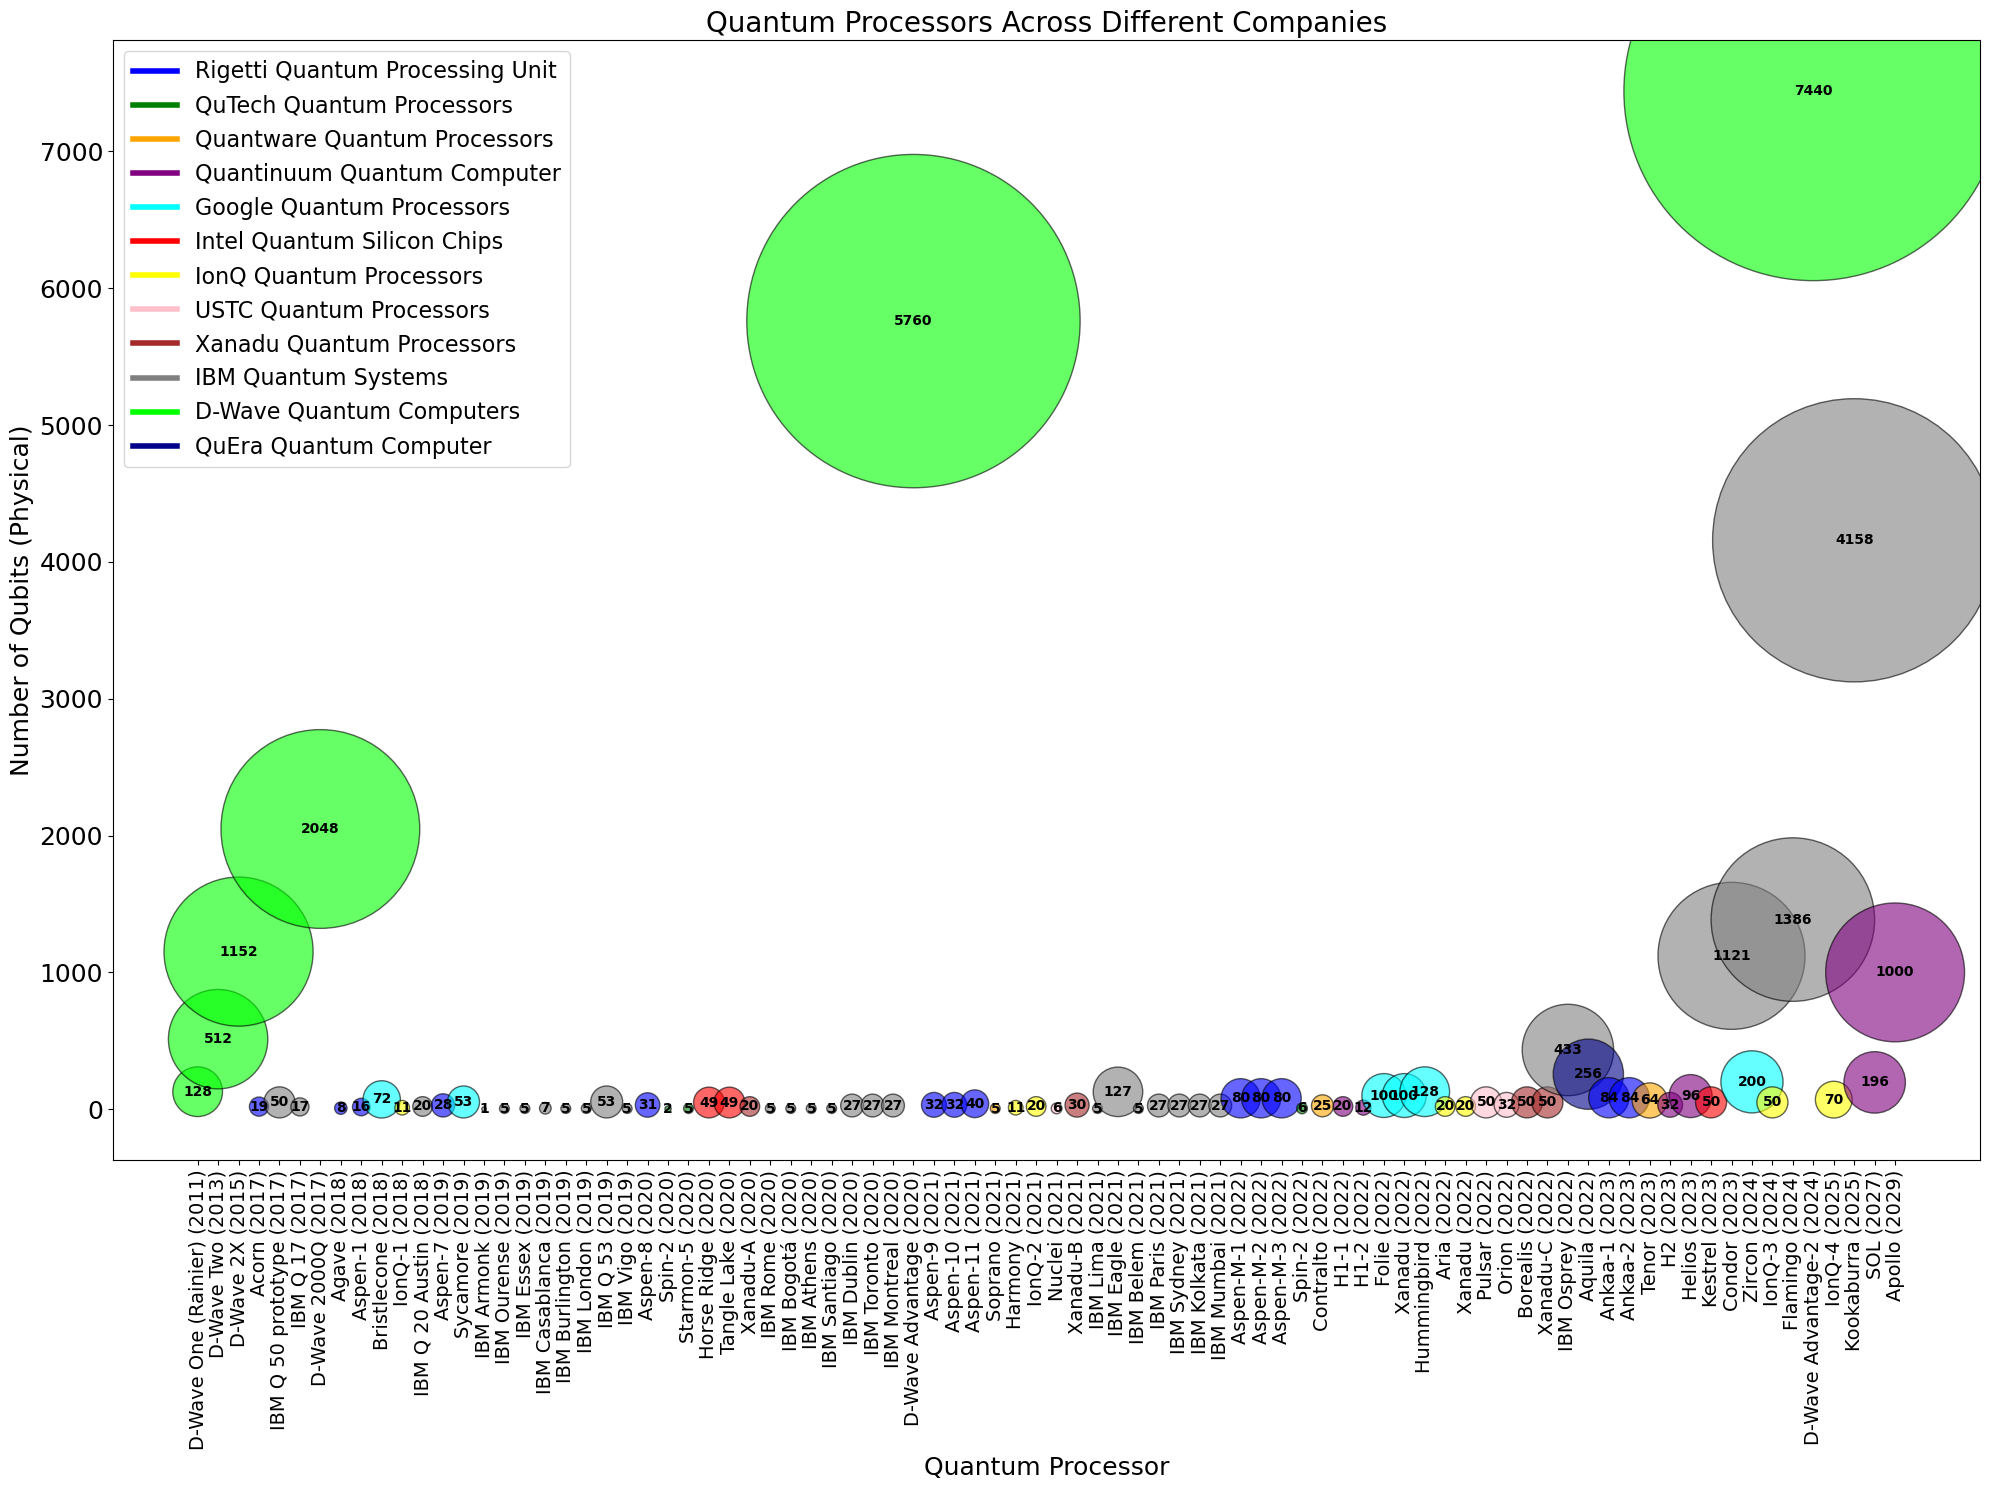

In [59]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Data for all processors as already defined above...
processors_all = (
    processors_rigetti + processors_qutech + processors_quantware + processors_quantinuum +
    processors_google + processors_intel + processors_ionq + processors_ustc + processors_xanadu +
    processors_ibm + processors_dw + processors_quera
)
qubits_all = (
    qubits_rigetti + qubits_qutech + qubits_quantware + qubits_quantinuum +
    qubits_google + qubits_intel + qubits_ionq + qubits_ustc + qubits_xanadu +
    qubits_ibm + qubits_dw + qubits_quera
)
colors_all = (
    ['blue']*len(processors_rigetti) + ['green']*len(processors_qutech) + ['orange']*len(processors_quantware) + ['purple']*len(processors_quantinuum) +
    ['cyan']*len(processors_google) + ['red']*len(processors_intel) + ['yellow']*len(processors_ionq) + ['pink']*len(processors_ustc) +
    ['brown']*len(processors_xanadu) + ['gray']*len(processors_ibm) + ['lime']*len(processors_dw) + ['darkblue']*len(processors_quera)
)

# Extract years from the processor names
def extract_year(processor_name):
    # Extract the year from the parentheses, e.g., "Acorn (2017)" -> 2017
    return int(processor_name.split('(')[-1].split(')')[0])

# Sort processors based on the extracted year
sorted_processors_and_qubits = sorted(zip(processors_all, qubits_all, colors_all), key=lambda x: extract_year(x[0]))

# Unzip the sorted data
processors_all_sorted, qubits_all_sorted, colors_all_sorted = zip(*sorted_processors_and_qubits)

# Set sizes for the bubbles based on the number of qubits
bubble_sizes = [q * 10 for q in qubits_all_sorted]  # Scale the bubble size by 10

# Create the bubble plot
plt.figure(figsize=(20, 15))

# Scatter plot: x-axis is the processor name (index), y-axis is the number of qubits, size is determined by `bubble_sizes`, and color by company
plt.scatter(range(len(processors_all_sorted)), qubits_all_sorted, s=bubble_sizes, c=colors_all_sorted, alpha=0.6, edgecolors="black", linewidth=1)

# Adding qubit values inside the bubbles with black color and bold text
for i, (x, y, size, qubit) in enumerate(zip(range(len(processors_all_sorted)), qubits_all_sorted, bubble_sizes, qubits_all_sorted)):
    # Adjust position slightly to make sure the text fits in the bubble
    plt.text(x, y, str(qubit), ha='center', va='center', fontsize=10, color='black', fontweight='bold')

# Adding titles and labels
plt.title("Quantum Processors Across Different Companies", fontsize=20)
plt.xlabel("Quantum Processor", fontsize=18)
plt.ylabel("Number of Qubits (Physical)", fontsize=18)

# Adjusting x-ticks and labels
plt.xticks(range(len(processors_all_sorted)), processors_all_sorted, rotation=90, ha='center', fontsize=14)

# Adjusting y-ticks font size to 18
plt.yticks(fontsize=18)

# Adding the legend
legend_elements = [
    Line2D([0], [0], color='blue', lw=4, label='Rigetti Quantum Processing Unit'),
    Line2D([0], [0], color='green', lw=4, label='QuTech Quantum Processors'),
    Line2D([0], [0], color='orange', lw=4, label='Quantware Quantum Processors'),
    Line2D([0], [0], color='purple', lw=4, label='Quantinuum Quantum Computer'),
    Line2D([0], [0], color='cyan', lw=4, label='Google Quantum Processors'),
    Line2D([0], [0], color='red', lw=4, label='Intel Quantum Silicon Chips'),
    Line2D([0], [0], color='yellow', lw=4, label='IonQ Quantum Processors'),
    Line2D([0], [0], color='pink', lw=4, label='USTC Quantum Processors'),
    Line2D([0], [0], color='brown', lw=4, label='Xanadu Quantum Processors'),
    Line2D([0], [0], color='gray', lw=4, label='IBM Quantum Systems'),
    Line2D([0], [0], color='lime', lw=4, label='D-Wave Quantum Computers'),
    Line2D([0], [0], color='darkblue', lw=4, label='QuEra Quantum Computer')
]
plt.legend(handles=legend_elements, fontsize=16)

# Display the plot
plt.tight_layout()
# Saving the plot to the specified directory
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\allquatum.png')
plt.show()




In [4]:
from graphviz import Digraph

# Create a Digraph object
tree = Digraph("QuantumNoiseMitigation", format="png")

# Add the main heading
tree.node("Main", "Noise Mitigation in Quantum", shape="rectangle", style="filled", color="lightblue")

# Add categories
categories = [
    ("QubitMapping", "Qubit Mapping"),
    ("ErrorSuppression", "Error Suppression"),
    ("ErrorMitigation", "Error Mitigation"),
    ("ErrorCorrection", "Error Correction")
]

for category_id, category_name in categories:
    tree.node(category_id, category_name, shape="ellipse", style="filled", color="lightgreen")
    tree.edge("Main", category_id)

# Add techniques under each category
techniques = {
    "QubitMapping": [
        "Qubit Placement Optimization",
        "Dynamic Circuit Routing",
        "Connectivity Matching",
        "Swap Gate Reduction",
        "Layout Heuristics",
        "Gate Decomposition Optimization",
        "Physical-to-Logical Qubit Mapping",
        "Placement Algorithms",
    ],
    "ErrorSuppression": [
        "Improved Material Engineering",
        "Cryogenic Cooling",
        "High-Fidelity Gates",
        "Quantum Control Techniques",
        "Reducing Crosstalk",
        "Decoherence-Free Subspaces",
        "Pulse Shaping",
        "Hardware Noise Filtering",
    ],
    "ErrorMitigation": [
        "Extrapolation Methods",
        "Probabilistic Error Cancellation",
        "Zero Noise Extrapolation",
        "Resampling Techniques",
        "Noise-aware Quantum Compilation",
        "Classical Post-processing",
        "Symmetry Verification",
        "Error Weighting Algorithms",
    ],
    "ErrorCorrection": [
        "Surface Code",
        "Shor's Code",
        "Steane Code",
        "Concatenated Codes",
        "Stabilizer Codes",
        "Color Codes",
        "Topological Codes",
        "Fault-Tolerant Gate Implementation",
    ]
}

# Add techniques to the tree
for category_id, tech_list in techniques.items():
    for i, technique in enumerate(tech_list):
        tech_id = f"{category_id}_{i}"
        tree.node(tech_id, technique, shape="plaintext")
        tree.edge(category_id, tech_id)

# Render the tree to a file
tree.render("quantum_noise_mitigation_tree", view=True)


ExecutableNotFound: failed to execute WindowsPath('dot'), make sure the Graphviz executables are on your systems' PATH

# A- Circuit Quantum Computers /Processors

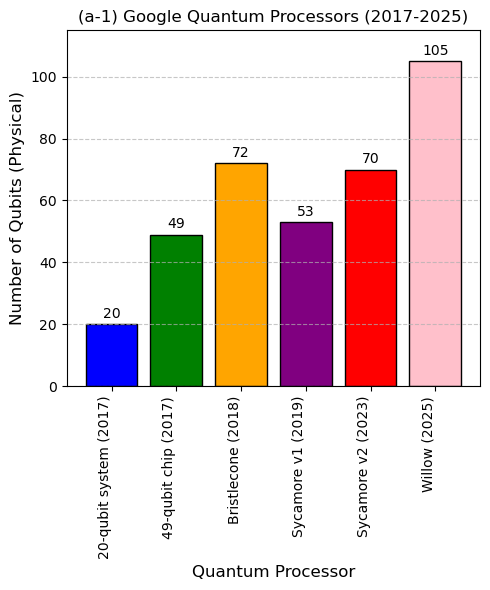

In [128]:
import matplotlib.pyplot as plt

# Data for the bar graph
processors = [
    "20-qubit system (2017)",
    "49-qubit chip (2017)",
    "Bristlecone (2018)",
    "Sycamore v1 (2019)",
    "Sycamore v2 (2023)", 
    "Willow (2025)"
]
qubits = [20, 49, 72, 53, 70, 105]

# Creating the bar graph with qubit values displayed on the bars
plt.figure(figsize=(5, 6))
bars = plt.bar(processors, qubits, color=['blue', 'green', 'orange', 'purple', 'red', 'pink'], width=0.8, edgecolor='black')
plt.ylim(0, max(qubits) + 10)

# Adding titles and labels
plt.title("(a-1) Google Quantum Processors (2017-2025)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the bar graph
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\1Google Quantum Processors.png')
plt.show()


In [6]:
import pandas as pd

# Data for IBM quantum processors
data = {
    "Name": [
        "IBM Armonk", "IBM Ourense", "IBM Vigo", "IBM London", "IBM Burlington", "IBM Essex",
        "IBM Athens", "IBM Bogotá", "IBM Santiago", "IBM Rome", "IBM Casablanca", 
        "IBM Belem", "IBM Lima", "IBM Dublin", "IBM Kolkata", "IBM Montreal", 
        "IBM Mumbai", "IBM Paris", "IBM Sydney", "IBM Toronto", 
        "IBM Q 17", "IBM Q 20 Austin", "IBM Q 50 prototype", "IBM Q 53", 
        "IBM Eagle", "IBM Osprey", "Condor", "Flamingo", "Kookaburra"
    ],
    "Qubits (Physical)": [
        1, 5, 5, 5, 5, 5, 5, 5, 5, 5, 7, 5, 5, 27, 27, 27, 27, 27, 27, 27,
        17, 20, 50, 53, 127, 433, 1121, 1386, 4158
    ],
    "Release Date": [
        "16-Oct-19", "3-Jul-19", "3-Jul-19", "13-Sep-19", "13-Sep-19", "13-Sep-19",
        "2020", "2020", "2020", "2020", "2019", 
        "2021", "2021", "2020", "2021", "2020", 
        "2021", "2021", "2021", "2020", 
        "17-May-17", "4-Jul-18", "Nov-17", "Oct-19", 
        "Nov-21", "Nov-22", "2023", "2024", "2025"
    ]
}

# Create a DataFrame
df = pd.DataFrame(data)

# Sort the data by Qubits (Physical)
df_sorted = df.sort_values(by="Qubits (Physical)")

df_sorted


,Name,Qubits (Physical),Release Date
0,IBM Armonk,1,16-Oct-19
12,IBM Lima,5,2021
11,IBM Belem,5,2021
9,IBM Rome,5,2020
7,IBM Bogotá,5,2020
6,IBM Athens,5,2020
8,IBM Santiago,5,2020
4,IBM Burlington,5,13-Sep-19
3,IBM London,5,13-Sep-19
2,IBM Vigo,5,3-Jul-19


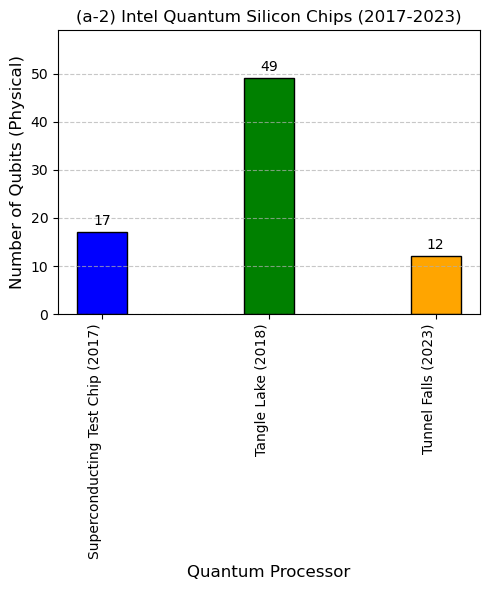

In [152]:
import matplotlib.pyplot as plt

# Data for the bar graph
processors = [
    "Superconducting Test Chip (2017)",
    "Tangle Lake (2018)",
    "Tunnel Falls (2023)"
]
qubits = [17, 49, 12]

# Creating the bar graph with a bar width of 0.3 and qubit values displayed on the bars
plt.figure(figsize=(5, 6))
bars = plt.bar(processors, qubits, color=['blue', 'green', 'orange'], width=0.3, edgecolor='black')

# Setting the y-axis limit to be 10 greater than the maximum qubit value
plt.ylim(0, max(qubits) + 10)

# Adding titles and labels
plt.title("(a-2) Intel Quantum Silicon Chips (2017-2023)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the bar graph
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\3.Intel Quantum Silicon Chips.png')
plt.show()


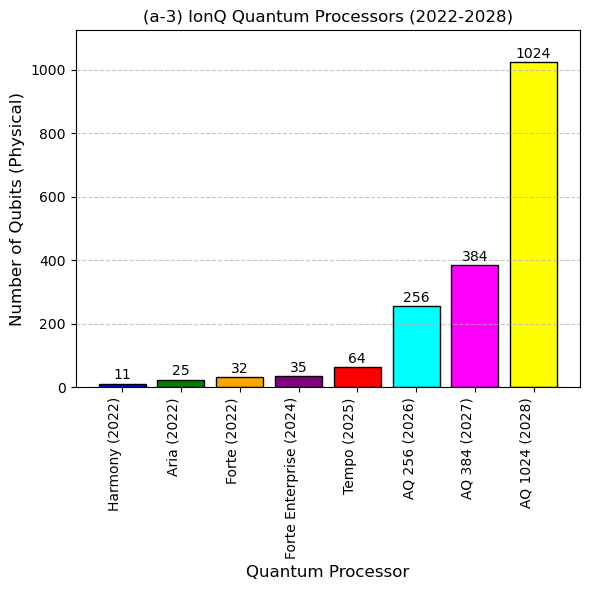

In [153]:
import matplotlib.pyplot as plt

# Data for the bar graph
processors = [
    "Harmony (2022)",
    "Aria (2022)",
    "Forte (2022)",
    "Forte Enterprise (2024)",
    "Tempo (2025)",
    "AQ 256 (2026)",
    "AQ 384 (2027)",
    "AQ 1024 (2028)"
]
qubits = [11, 25, 32, 35, 64, 256, 384, 1024]

# Creating the bar graph with a bar width of 0.3 and qubit values displayed on the bars
plt.figure(figsize=(6, 6))
bars = plt.bar(processors, qubits, color=['blue', 'green', 'orange', 'purple', 'red', 'cyan', 'magenta', 'yellow'], width=0.8, edgecolor='black')

# Setting the y-axis limit to be 10 greater than the maximum qubit value
plt.ylim(0, max(qubits) + 100)

# Adding titles and labels
plt.title("(a-3) IonQ Quantum Processors (2022-2028)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the bar graph
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\4.IonQ Quantum Processors.png')
plt.show()


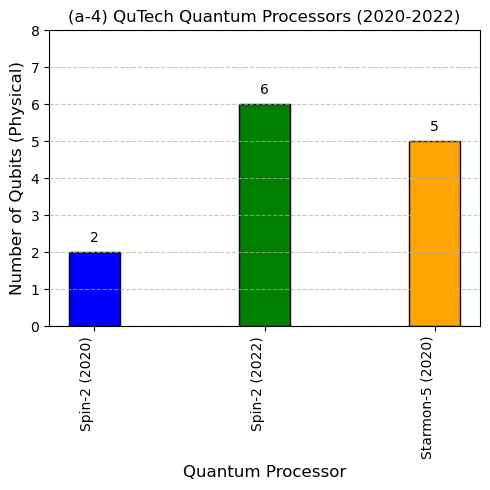

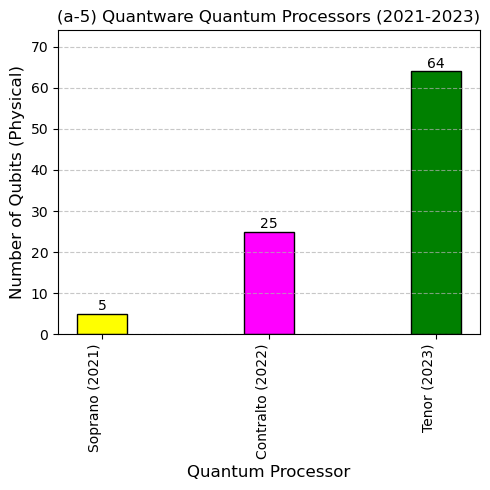

In [154]:
import matplotlib.pyplot as plt

# Data for QuTech Quantum Processors
processors_1 = [
    "Spin-2 (2020)", "Spin-2 (2022)", "Starmon-5 (2020)"
]
qubits_1 = [2, 6, 5]


# Data for Quantware Quantum Processors
processors_3 = [
    "Soprano (2021)", "Contralto (2022)", "Tenor (2023)"
]
qubits_3 = [5, 25, 64]

# Plotting the QuTech Quantum Processors
plt.figure(figsize=(5, 5))
bars_1 = plt.bar(processors_1, qubits_1, color=['blue', 'green', 'orange'], width=0.3, edgecolor='black')
plt.title("(a-4) QuTech Quantum Processors (2020-2022)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.ylim(0, max(qubits_1) + 2)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for bar, qubit in zip(bars_1, qubits_1):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, 
             str(qubit), ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\5.QuTech Quantum Processors.png')
plt.show()


# Plotting the Quantware Quantum Processors
plt.figure(figsize=(5, 5))
bars_3 = plt.bar(processors_3, qubits_3, color=['yellow', 'magenta', 'green'], width=0.3, edgecolor='black')
plt.title("(a-5) Quantware Quantum Processors (2021-2023)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.ylim(0, max(qubits_3) + 10)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
for bar, qubit in zip(bars_3, qubits_3):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, 
             str(qubit), ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\6.Quantware Quantum Processor.png')
plt.show()


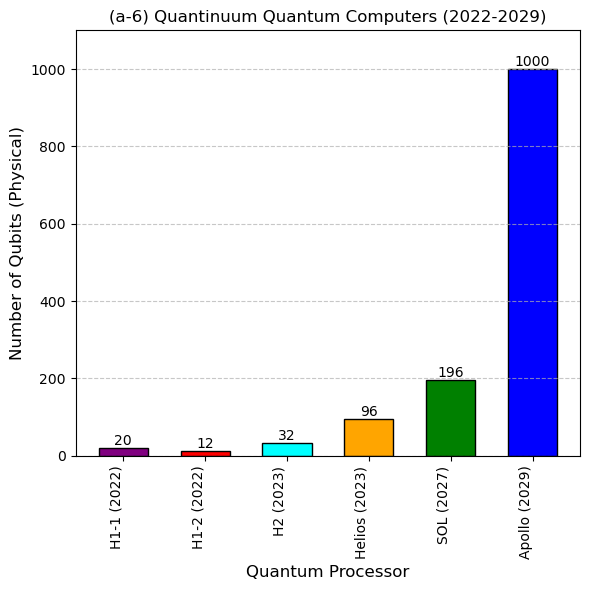

In [155]:
import matplotlib.pyplot as plt

# Data for Quantinuum Quantum Computers (with new processors added)
processors_2 = [
    "H2 (2023)", "H1-1 (2022)", "H1-2 (2022)",
    "Helios (2023)", "SOL (2027)", "Apollo (2029)"
]
qubits_2 = [32, 20, 12, 96, 196, 1000]

# Extract years from the processor names for sorting
years_2 = [int(proc.split('(')[-1].split(')')[0]) for proc in processors_2]

# Sorting the data by the extracted year
sorted_data_2 = sorted(zip(processors_2, qubits_2, years_2), key=lambda x: x[2])

# Unzip the sorted data back into separate lists
processors_sorted_2, qubits_sorted_2, years_sorted_2 = zip(*sorted_data_2)

# Plotting the Quantinuum Quantum Computers graph
plt.figure(figsize=(6, 6))
bars_2 = plt.bar(processors_sorted_2, qubits_sorted_2, color=['purple', 'red', 'cyan', 'orange', 'green', 'blue'], width=0.6, edgecolor='black')

# Adding titles and labels
plt.title("(a-6) Quantinuum Quantum Computers (2022-2029)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.ylim(0, max(qubits_sorted_2) + 100)

# Rotating x-axis labels for readability
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars_2, qubits_sorted_2):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.2, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the plot
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\7.Quantinuum Quantum Computers.png')
plt.show()


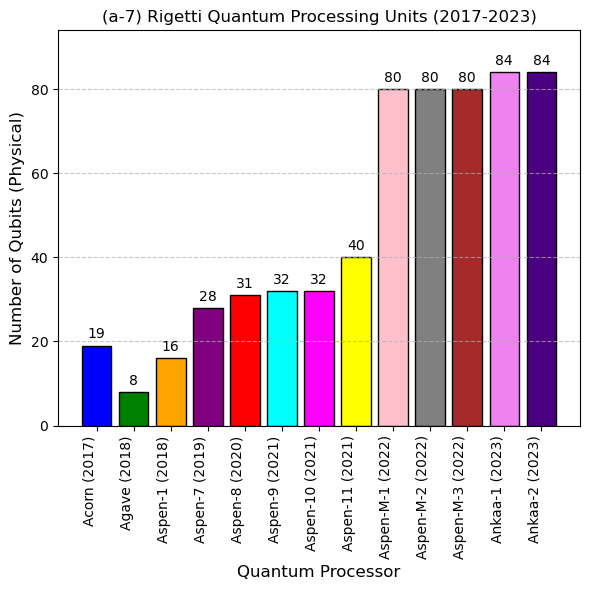

In [156]:
import matplotlib.pyplot as plt

# Data for Rigetti Quantum Processing Units (with year included for sorting)
processors = [
    "Acorn (2017)", "Agave (2018)", "Aspen-1 (2018)",
    "Aspen-7 (2019)", "Aspen-8 (2020)", "Aspen-9 (2021)",
    "Aspen-10 (2021)", "Aspen-11 (2021)", "Aspen-M-1 (2022)",
    "Aspen-M-2 (2022)", "Aspen-M-3 (2022)", "Ankaa-1 (2023)", "Ankaa-2 (2023)"
]
qubits = [19, 8, 16, 28, 31, 32, 32, 40, 80, 80, 80, 84, 84]

# Extract years from the processor names for sorting
years = [int(proc.split('(')[-1].split(')')[0]) for proc in processors]

# Sorting the data by the extracted year
sorted_data = sorted(zip(processors, qubits, years), key=lambda x: x[2])

# Unzip the sorted data back into separate lists
processors_sorted, qubits_sorted, years_sorted = zip(*sorted_data)

# Creating the bar graph with qubit values displayed on the bars
plt.figure(figsize=(6, 6))
bars = plt.bar(processors_sorted, qubits_sorted, color=['blue', 'green', 'orange', 'purple', 'red', 'cyan', 'magenta', 'yellow', 'pink', 'gray', 'brown', 'violet', 'indigo'], width=0.8, edgecolor='black')

# Setting the y-axis limit to be 10 greater than the maximum qubit value
plt.ylim(0, max(qubits_sorted) + 10)

# Adding titles and labels
plt.title("(a-7) Rigetti Quantum Processing Units (2017-2023)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits_sorted):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the bar graph
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\8.Rigetti Quantum Processing.png')
plt.show()


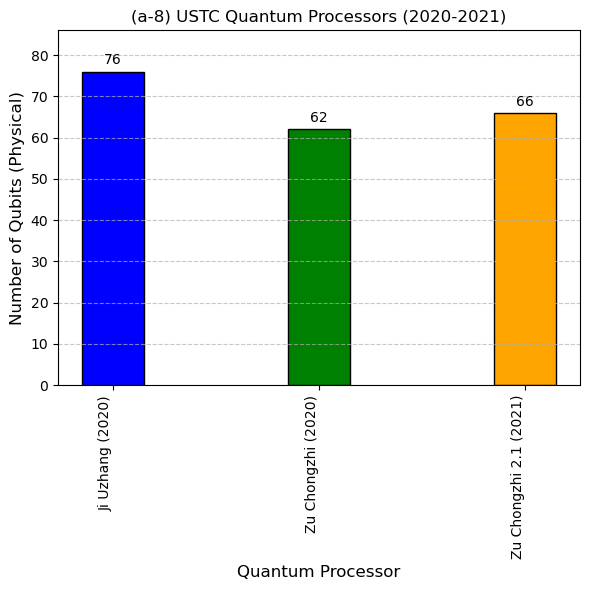

In [157]:
import matplotlib.pyplot as plt

# Data for USTC Quantum Processors
processors = [
    "Ji Uzhang (2020)", "Zu Chongzhi (2020)", "Zu Chongzhi 2.1 (2021)"
]
qubits = [76, 62, 66]
release_dates = ["2020", "2020", "2021"]

# Sorting the data by release date
sorted_data = sorted(zip(processors, qubits, release_dates), key=lambda x: x[2])

# Unzip the sorted data back into separate lists
processors_sorted, qubits_sorted, release_dates_sorted = zip(*sorted_data)

# Creating the bar graph with qubit values displayed on the bars
plt.figure(figsize=(6, 6))
bars = plt.bar(processors_sorted, qubits_sorted, color=['blue', 'green', 'orange'], width=0.3, edgecolor='black')

# Setting the y-axis limit to be 10 greater than the maximum qubit value
plt.ylim(0, max(qubits_sorted) + 10)

# Adding titles and labels
plt.title("(a-8) USTC Quantum Processors (2020-2021)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits_sorted):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the bar graph
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\9.USTC Quantum Processors.png')
plt.show()


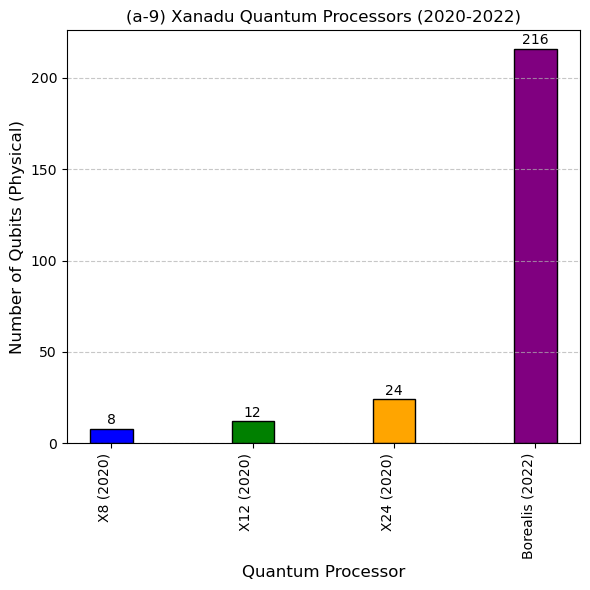

In [158]:
import matplotlib.pyplot as plt

# Data for Xanadu Quantum Processors
processors = [
    "Borealis (2022)", "X8 (2020)", "X12 (2020)", "X24 (2020)"
]
qubits = [216, 8, 12, 24]
release_dates = ["2022", "2020", "2020", "2020"]

# Sorting the data by release date
sorted_data = sorted(zip(processors, qubits, release_dates), key=lambda x: x[2])

# Unzip the sorted data back into separate lists
processors_sorted, qubits_sorted, release_dates_sorted = zip(*sorted_data)

# Creating the bar graph with qubit values displayed on the bars
plt.figure(figsize=(6, 6))
bars = plt.bar(processors_sorted, qubits_sorted, color=['blue', 'green', 'orange', 'purple'], width=0.3, edgecolor='black')

# Setting the y-axis limit to be 10 greater than the maximum qubit value
plt.ylim(0, max(qubits_sorted) + 10)

# Adding titles and labels
plt.title("(a-9) Xanadu Quantum Processors (2020-2022)", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits_sorted):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the bar graph
plt.tight_layout()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\10Xanadu Quantum Processors.png')
plt.show()


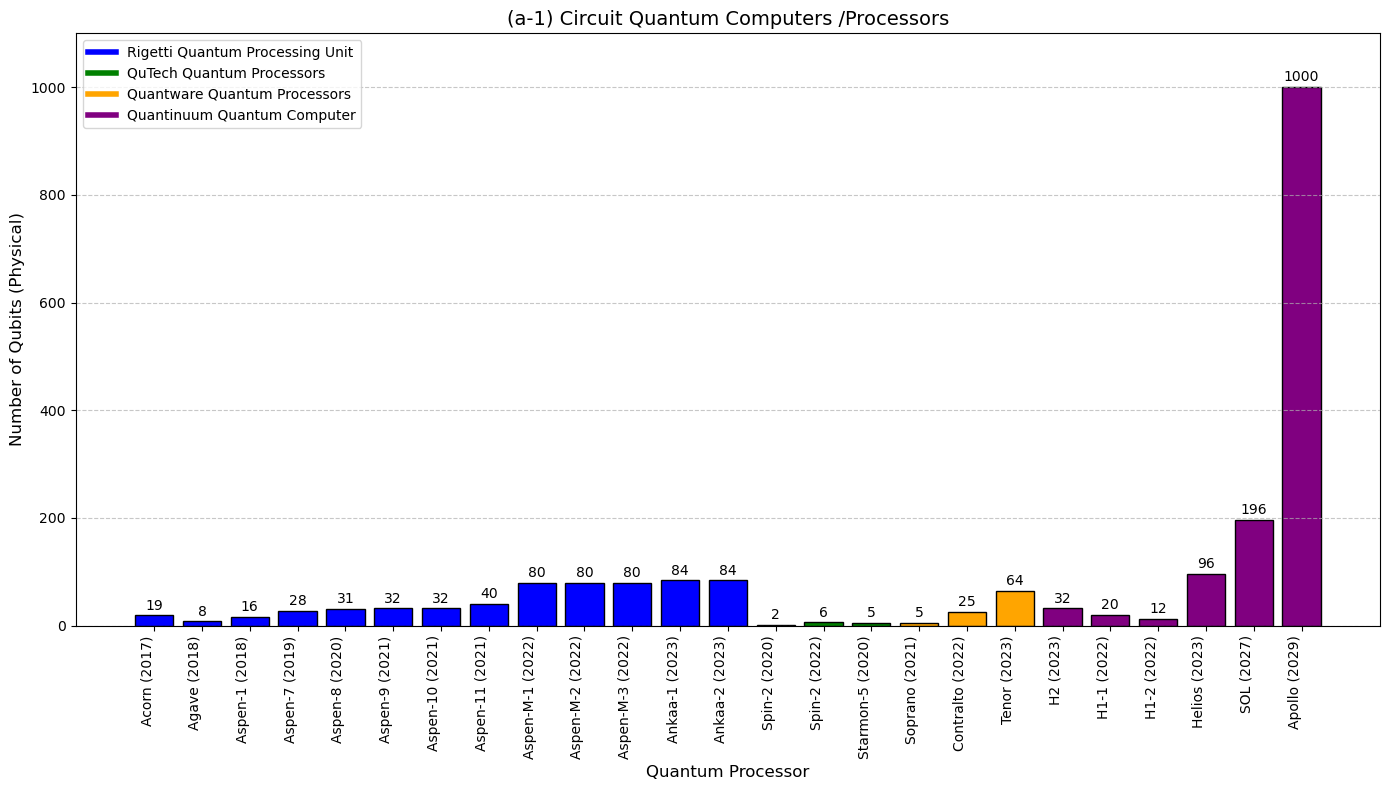

In [179]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Data for Rigetti Quantum Processing Units (2017-2023)
processors_rigetti = [
    "Acorn (2017)", "Agave (2018)", "Aspen-1 (2018)", "Aspen-7 (2019)", "Aspen-8 (2020)", 
    "Aspen-9 (2021)", "Aspen-10 (2021)", "Aspen-11 (2021)", "Aspen-M-1 (2022)", "Aspen-M-2 (2022)",
    "Aspen-M-3 (2022)", "Ankaa-1 (2023)", "Ankaa-2 (2023)"
]
qubits_rigetti = [19, 8, 16, 28, 31, 32, 32, 40, 80, 80, 80, 84, 84]

# Data for QuTech Quantum Processors (2020-2022)
processors_qutech = [
    "Spin-2 (2020)", "Spin-2 (2022)", "Starmon-5 (2020)"
]
qubits_qutech = [2, 6, 5]

# Data for Quantware Quantum Processors (2021-2023)
processors_quantware = [
    "Soprano (2021)", "Contralto (2022)", "Tenor (2023)"
]
qubits_quantware = [5, 25, 64]

# Data for Quantinuum Quantum Computers (2022-2029)
processors_quantinuum = [
    "H2 (2023)", "H1-1 (2022)", "H1-2 (2022)", "Helios (2023)", "SOL (2027)", "Apollo (2029)"
]
qubits_quantinuum = [32, 20, 12, 96, 196, 1000]

# Combine all processors and qubits for plotting
processors = processors_rigetti + processors_qutech + processors_quantware + processors_quantinuum
qubits = qubits_rigetti + qubits_qutech + qubits_quantware + qubits_quantinuum

# Define colors for each group
colors = ['blue']*len(processors_rigetti) + ['green']*len(processors_qutech) + ['orange']*len(processors_quantware) + ['purple']*len(processors_quantinuum)

# Create the bar graph
plt.figure(figsize=(14, 8))
bars = plt.bar(processors, qubits, color=colors, width=0.8, edgecolor='black')

# Setting the y-axis limit to be 10 greater than the maximum qubit value
plt.ylim(0, max(qubits) + 100)

# Adding titles and labels
plt.title("(a-1) Circuit Quantum Computers /Processors", fontsize=14)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Adding a legend
legend_elements = [
    Line2D([0], [0], color='blue', lw=4, label='Rigetti Quantum Processing Unit'),
    Line2D([0], [0], color='green', lw=4, label='QuTech Quantum Processors'),
    Line2D([0], [0], color='orange', lw=4, label='Quantware Quantum Processors'),
    Line2D([0], [0], color='purple', lw=4, label='Quantinuum Quantum Computer')
]
plt.legend(handles=legend_elements, fontsize=10)

# Displaying the bar graph
plt.tight_layout()
#plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quantum-computer\\combined_quantum_processors.png')
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\a1Quantum Systems.png')
plt.show()


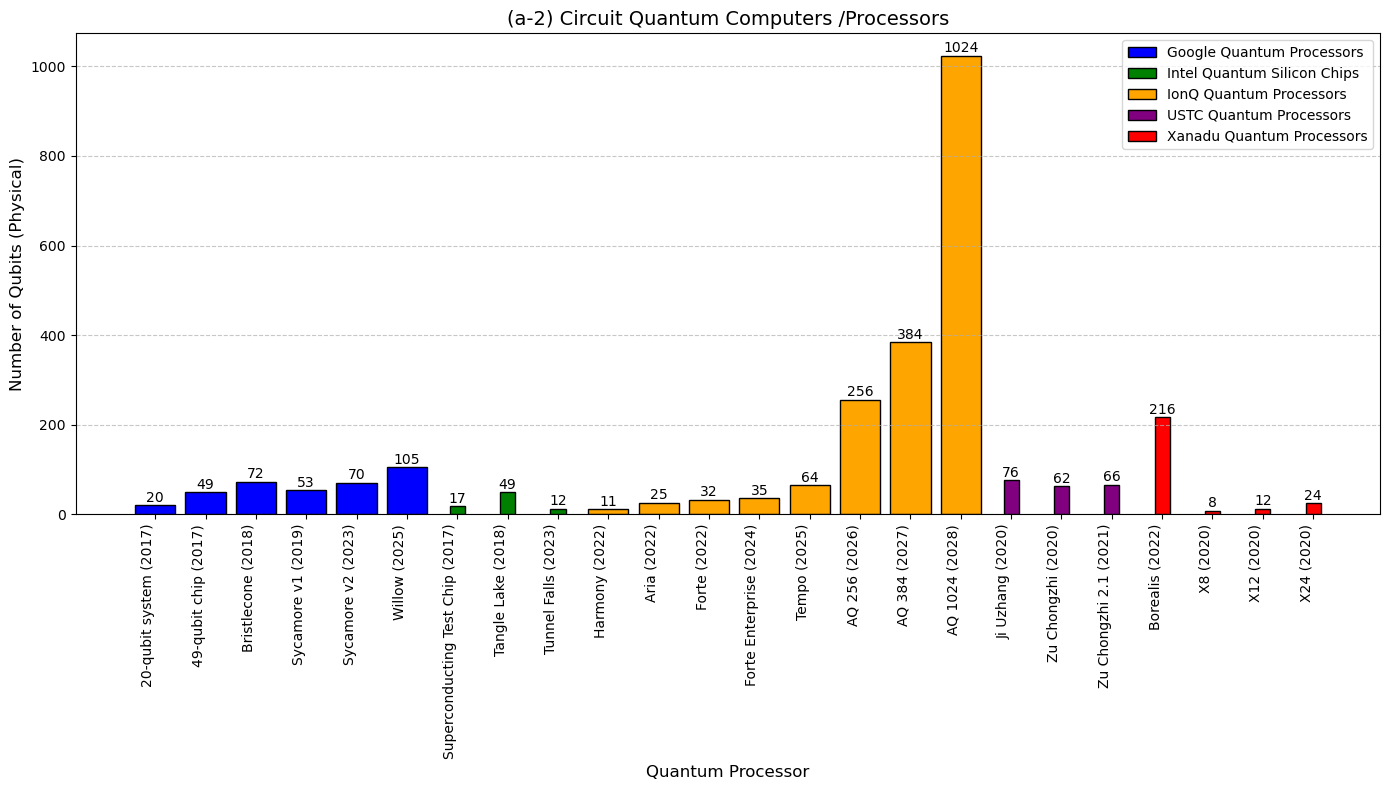

In [180]:
import matplotlib.pyplot as plt

# Data for each group
processors_1 = [
    "20-qubit system (2017)", "49-qubit chip (2017)", "Bristlecone (2018)", 
    "Sycamore v1 (2019)", "Sycamore v2 (2023)", "Willow (2025)"
]
qubits_1 = [20, 49, 72, 53, 70, 105]
processors_2 = [
    "Superconducting Test Chip (2017)", "Tangle Lake (2018)", "Tunnel Falls (2023)"
]
qubits_2 = [17, 49, 12]
processors_3 = [
    "Harmony (2022)", "Aria (2022)", "Forte (2022)", "Forte Enterprise (2024)", 
    "Tempo (2025)", "AQ 256 (2026)", "AQ 384 (2027)", "AQ 1024 (2028)"
]
qubits_3 = [11, 25, 32, 35, 64, 256, 384, 1024]
processors_4 = ["Ji Uzhang (2020)", "Zu Chongzhi (2020)", "Zu Chongzhi 2.1 (2021)"]
qubits_4 = [76, 62, 66]
processors_5 = ["Borealis (2022)", "X8 (2020)", "X12 (2020)", "X24 (2020)"]
qubits_5 = [216, 8, 12, 24]

# Creating the figure
plt.figure(figsize=(14, 8))

# Plotting bars for each group
bars1 = plt.bar(processors_1, qubits_1, color='blue', width=0.8, edgecolor='black', label='Google Quantum Processors')
bars2 = plt.bar(processors_2, qubits_2, color='green', width=0.3, edgecolor='black', label='Intel Quantum Silicon Chips')
bars3 = plt.bar(processors_3, qubits_3, color='orange', width=0.8, edgecolor='black', label='IonQ Quantum Processors')
bars4 = plt.bar(processors_4, qubits_4, color='purple', width=0.3, edgecolor='black', label='USTC Quantum Processors')
bars5 = plt.bar(processors_5, qubits_5, color='red', width=0.3, edgecolor='black', label='Xanadu Quantum Processors')

# Adjusting y-axis limit
plt.ylim(0, max(qubits_1 + qubits_2 + qubits_3 + qubits_4 + qubits_5) + 50)

# Adding titles and labels
plt.title("(a-2) Circuit Quantum Computers /Processors", fontsize=14)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bars, qubits in zip([bars1, bars2, bars3, bars4, bars5], 
                        [qubits_1, qubits_2, qubits_3, qubits_4, qubits_5]):
    for bar, qubit in zip(bars, qubits):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1, 
                 str(qubit), ha='center', va='bottom', fontsize=10)

# Adding the legend
plt.legend()
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\a2Quantum Systems.png')
# Displaying the plot
plt.tight_layout()
plt.show()


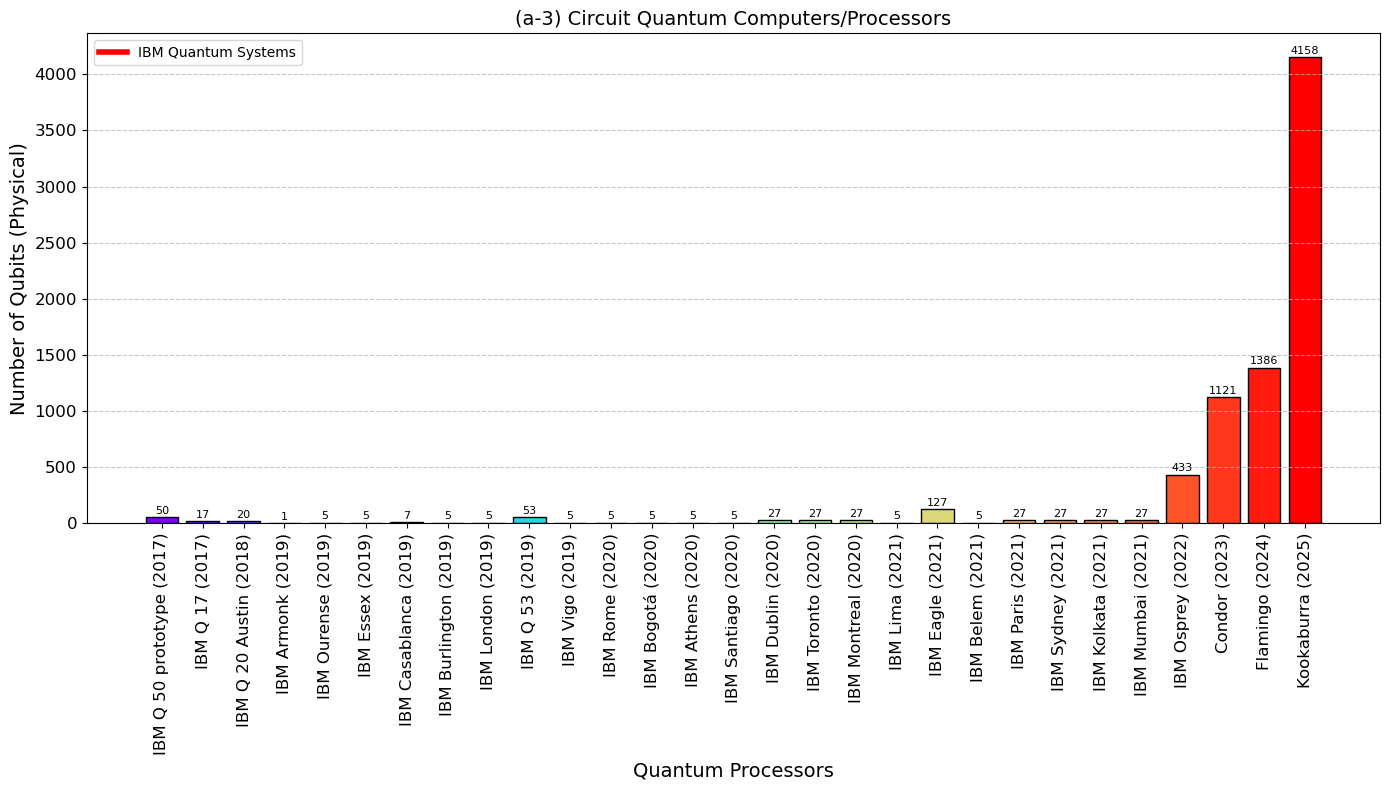

In [181]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np

# Data for IBM quantum processors sorted by release year and ascending qubits
processors = [
    "IBM Q 50 prototype (2017)", "IBM Q 17 (2017)", "IBM Q 20 Austin (2018)",
    "IBM Armonk (2019)", "IBM Ourense (2019)", "IBM Essex (2019)",
    "IBM Casablanca (2019)", "IBM Burlington (2019)", "IBM London (2019)",
    "IBM Q 53 (2019)", "IBM Vigo (2019)", "IBM Rome (2020)",
    "IBM Bogotá (2020)", "IBM Athens (2020)", "IBM Santiago (2020)",
    "IBM Dublin (2020)", "IBM Toronto (2020)", "IBM Montreal (2020)",
    "IBM Lima (2021)", "IBM Eagle (2021)", "IBM Belem (2021)",
    "IBM Paris (2021)", "IBM Sydney (2021)", "IBM Kolkata (2021)",
    "IBM Mumbai (2021)", "IBM Osprey (2022)", "Condor (2023)",
    "Flamingo (2024)", "Kookaburra (2025)"
]

qubits = [
    50, 17, 20, 1, 5, 5, 7, 5, 5, 53, 5, 5, 5, 5, 5, 27, 27, 27, 5, 127, 5,
    27, 27, 27, 27, 433, 1121, 1386, 4158
]

# Generate unique colors for each bar
colors = cm.rainbow(np.linspace(0, 1, len(processors)))

# Creating the bar graph with qubit values displayed on the bars
plt.figure(figsize=(14, 8))
bars = plt.bar(processors, qubits, color=colors, edgecolor='black')

# Adding titles and labels
plt.title("(a-3) Circuit Quantum Computers/Processors", fontsize=14)
plt.xlabel("Quantum Processors", fontsize=14)
plt.ylabel("Number of Qubits (Physical)", fontsize=14)
plt.xticks(rotation=90, ha='center', fontsize=12)
plt.yticks(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
             str(qubit), ha='center', va='bottom', fontsize=8)

# Displaying the bar graph
plt.tight_layout()
legend_elements = [
    Line2D([0], [0], color='red', lw=4, label='IBM Quantum Systems'),
]
plt.legend(handles=legend_elements, fontsize=10)

plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\a3Quantum Systems.png')
plt.show()


# B. Annealing Quantum Computers /Processors

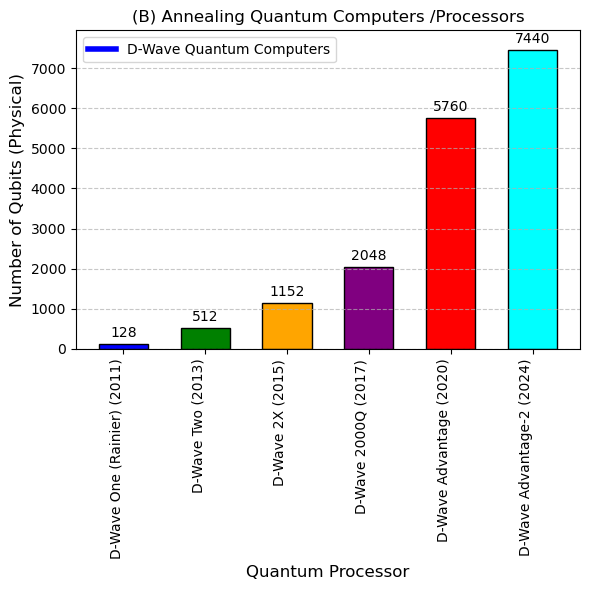

In [176]:
import matplotlib.pyplot as plt

# Data for D-Wave Quantum Computers (with year included for sorting)
processors_dw = [
    "D-Wave One (Rainier) (2011)", "D-Wave Two (2013)", "D-Wave 2X (2015)",
    "D-Wave 2000Q (2017)", "D-Wave Advantage (2020)", "D-Wave Advantage-2 (2024)"
]
qubits_dw = [128, 512, 1152, 2048, 5760, 7440]

# Extract years from the processor names for sorting
years_dw = [int(proc.split('(')[-1].split(')')[0]) for proc in processors_dw]

# Sorting the data by the extracted year
sorted_data_dw = sorted(zip(processors_dw, qubits_dw, years_dw), key=lambda x: x[2])

# Unzip the sorted data back into separate lists
processors_sorted_dw, qubits_sorted_dw, years_sorted_dw = zip(*sorted_data_dw)

# Plotting the D-Wave Quantum Computers graph
plt.figure(figsize=(6, 6))
bars_dw = plt.bar(processors_sorted_dw, qubits_sorted_dw, color=['blue', 'green', 'orange', 'purple', 'red', 'cyan'], width=0.6, edgecolor='black')

# Adding titles and labels
plt.title("(B) Annealing Quantum Computers /Processors", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.ylim(0, max(qubits_sorted_dw) + 500)

# Rotating x-axis labels for readability
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars_dw, qubits_sorted_dw):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 100, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the plot
plt.tight_layout()

# Adding a legend
legend_elements = [
    Line2D([0], [0], color='blue', lw=4, label='D-Wave Quantum Computers')
]
plt.legend(handles=legend_elements, fontsize=10) 
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\bQuantum Computers.png')
plt.show()


# C. Analog Quantum Computers /Processors

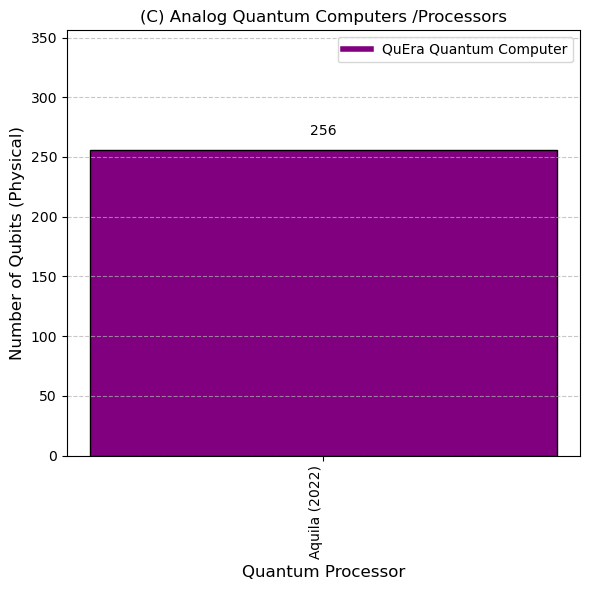

In [178]:
import matplotlib.pyplot as plt

# Data for QuEra Quantum Computer
processors_quera = ["Aquila (2022)"]
qubits_quera = [256]

# Plotting the QuEra Quantum Computer graph
plt.figure(figsize=(6, 6))
bars_quera = plt.bar(processors_quera, qubits_quera, color=['purple'], width=0.3, edgecolor='black')

# Adding titles and labels
plt.title("(C) Analog Quantum Computers /Processors", fontsize=12)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.ylim(0, max(qubits_quera) + 100)

# Rotating x-axis labels for readability
plt.xticks(rotation=90, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit value on top of the bar
for bar, qubit in zip(bars_quera, qubits_quera):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Displaying the plot
plt.tight_layout()
legend_elements = [
    Line2D([0], [0], color='purple', lw=4, label='QuEra Quantum Computer')
]
plt.legend(handles=legend_elements, fontsize=10) 
plt.savefig('D:\\Journals\\Quantum review paper\\Pictures\\quatum-computer\\cQuantum Computer.png')
plt.show()


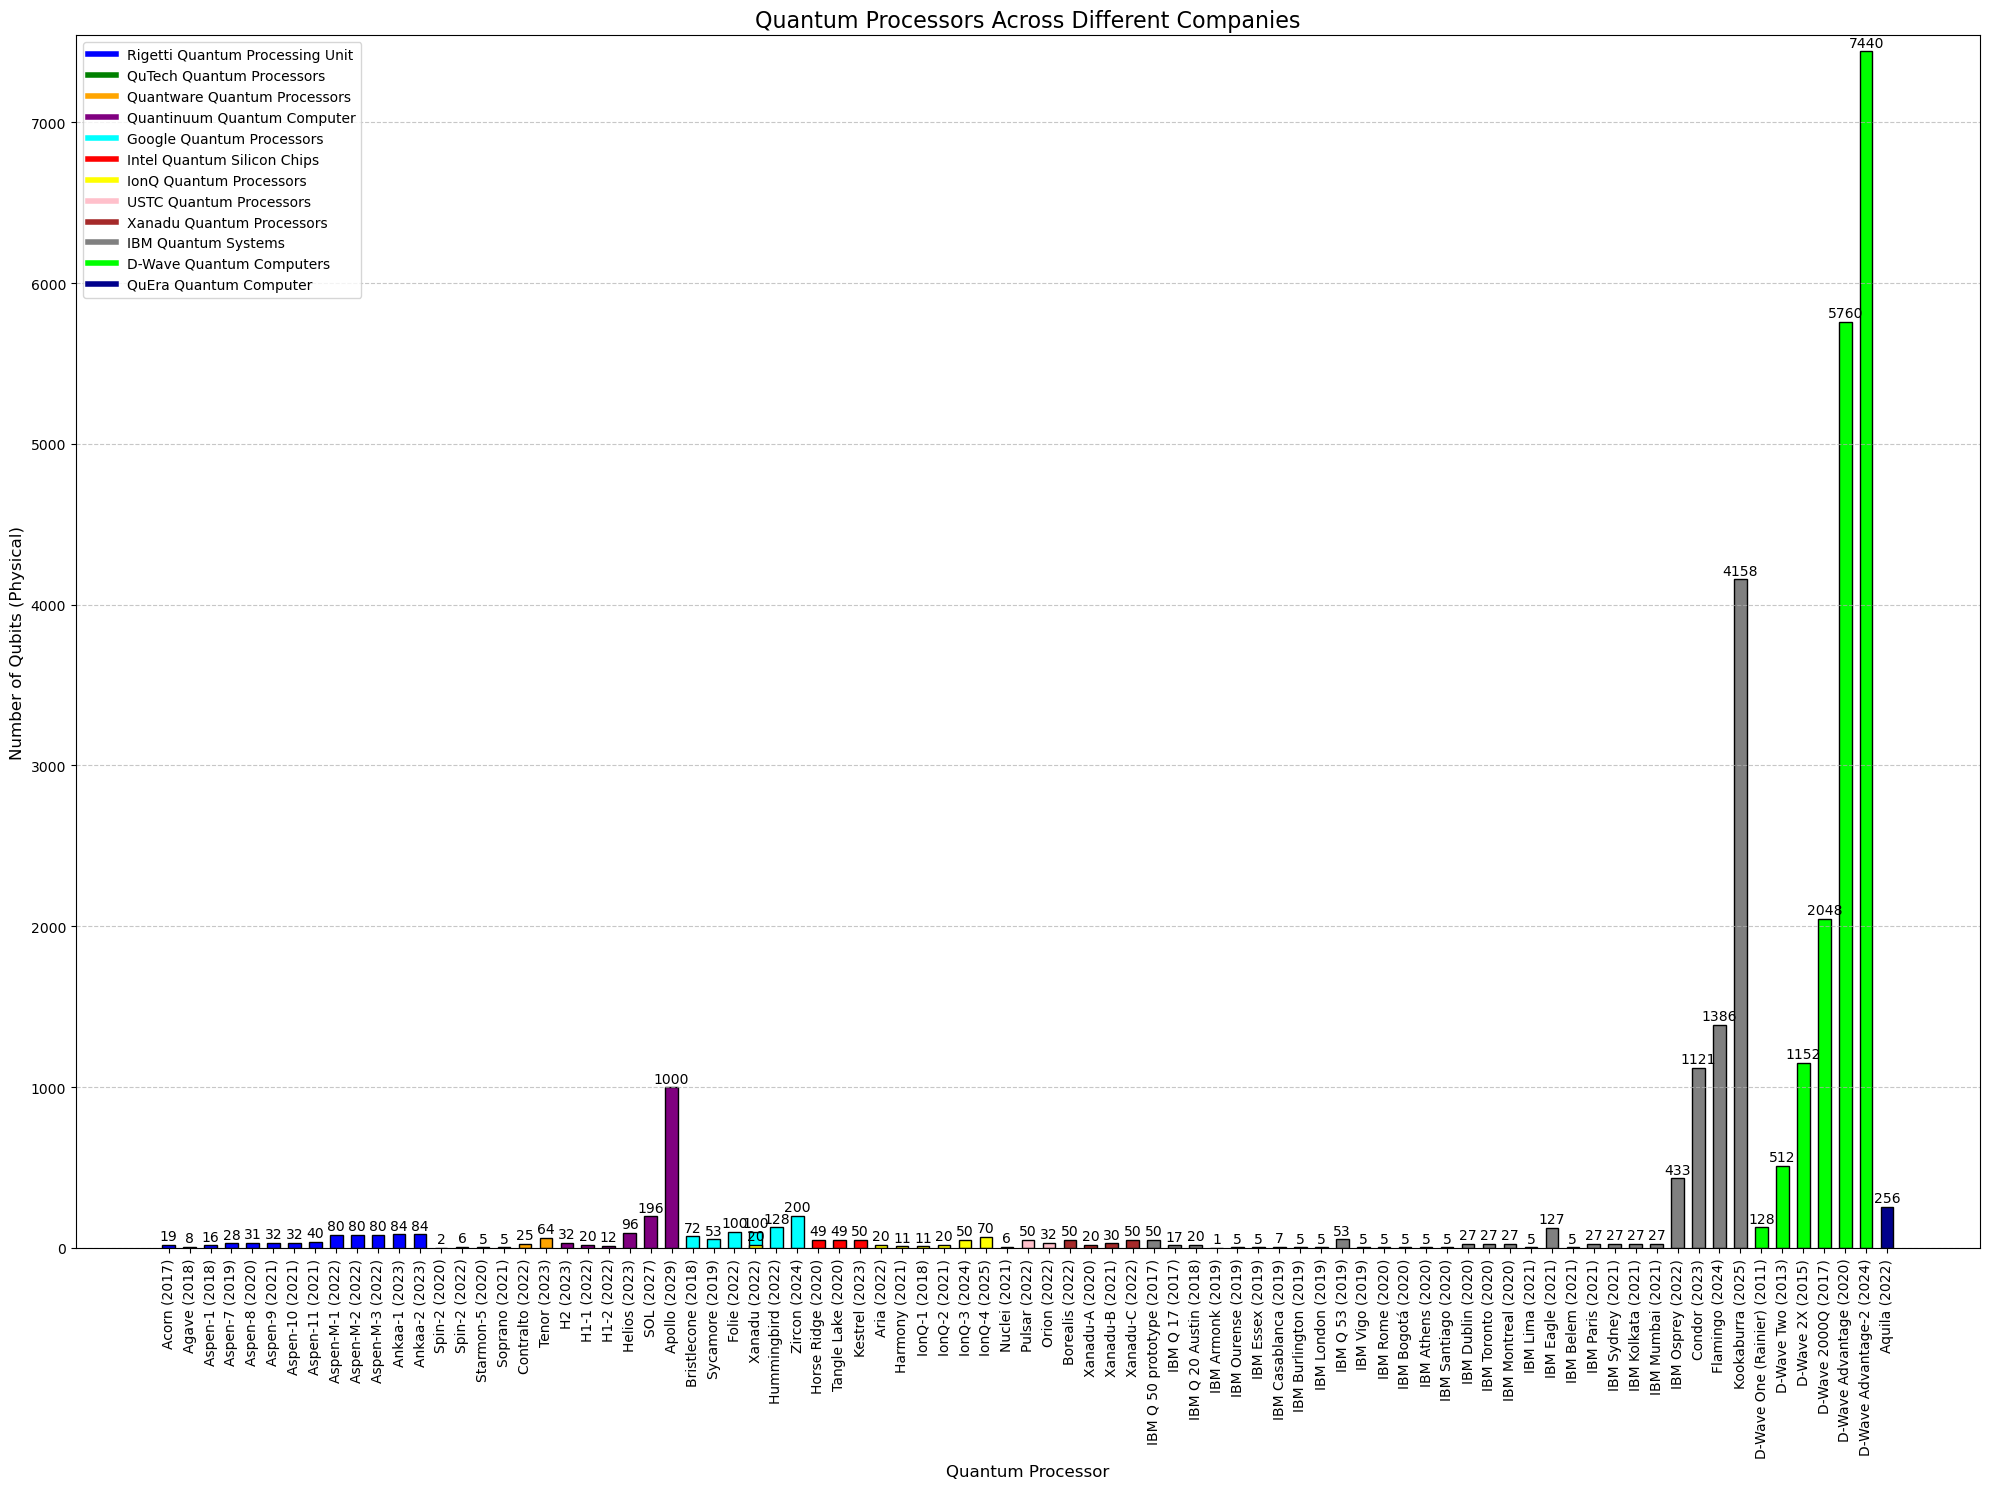

In [19]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Data for Rigetti Quantum Processing Units
processors_rigetti = [
    "Acorn (2017)", "Agave (2018)", "Aspen-1 (2018)", "Aspen-7 (2019)", "Aspen-8 (2020)", 
    "Aspen-9 (2021)", "Aspen-10 (2021)", "Aspen-11 (2021)", "Aspen-M-1 (2022)", "Aspen-M-2 (2022)",
    "Aspen-M-3 (2022)", "Ankaa-1 (2023)", "Ankaa-2 (2023)"
]
qubits_rigetti = [19, 8, 16, 28, 31, 32, 32, 40, 80, 80, 80, 84, 84]

# Data for QuTech Quantum Processors
processors_qutech = [
    "Spin-2 (2020)", "Spin-2 (2022)", "Starmon-5 (2020)"
]
qubits_qutech = [2, 6, 5]

# Data for Quantware Quantum Processors
processors_quantware = [
    "Soprano (2021)", "Contralto (2022)", "Tenor (2023)"
]
qubits_quantware = [5, 25, 64]

# Data for Quantinuum Quantum Computers
processors_quantinuum = [
    "H2 (2023)", "H1-1 (2022)", "H1-2 (2022)", "Helios (2023)", "SOL (2027)", "Apollo (2029)"
]
qubits_quantinuum = [32, 20, 12, 96, 196, 1000]

# Data for Google Quantum Processors
processors_google = [
    "Bristlecone (2018)", "Sycamore (2019)", "Folie (2022)", "Xanadu (2022)", "Hummingbird (2022)", "Zircon (2024)"
]
qubits_google = [72, 53, 100, 100, 128, 200]

# Data for Intel Quantum Silicon Chips
processors_intel = [
    "Horse Ridge (2020)", "Tangle Lake (2020)", "Kestrel (2023)"
]
qubits_intel = [49, 49, 50]

# Data for IonQ Quantum Processors
processors_ionq = [
    "Aria (2022)", "Harmony (2021)", "Xanadu (2022)", "IonQ-1 (2018)", "IonQ-2 (2021)", "IonQ-3 (2024)", "IonQ-4 (2025)"
]
qubits_ionq = [20, 11, 20, 11, 20, 50, 70]

# Data for USTC Quantum Processors
processors_ustc = [
    "Nuclei (2021)", "Pulsar (2022)", "Orion (2022)"
]
qubits_ustc = [6, 50, 32]

# Data for Xanadu Quantum Processors
processors_xanadu = [
    "Borealis (2022)", "Xanadu-A (2020)", "Xanadu-B (2021)", "Xanadu-C (2022)"
]
qubits_xanadu = [50, 20, 30, 50]

# Data for IBM Quantum Systems
processors_ibm = [
    "IBM Q 50 prototype (2017)", "IBM Q 17 (2017)", "IBM Q 20 Austin (2018)",
    "IBM Armonk (2019)", "IBM Ourense (2019)", "IBM Essex (2019)",
    "IBM Casablanca (2019)", "IBM Burlington (2019)", "IBM London (2019)",
    "IBM Q 53 (2019)", "IBM Vigo (2019)", "IBM Rome (2020)",
    "IBM Bogotá (2020)", "IBM Athens (2020)", "IBM Santiago (2020)",
    "IBM Dublin (2020)", "IBM Toronto (2020)", "IBM Montreal (2020)",
    "IBM Lima (2021)", "IBM Eagle (2021)", "IBM Belem (2021)",
    "IBM Paris (2021)", "IBM Sydney (2021)", "IBM Kolkata (2021)",
    "IBM Mumbai (2021)", "IBM Osprey (2022)", "Condor (2023)",
    "Flamingo (2024)", "Kookaburra (2025)"
]
qubits_ibm = [
    50, 17, 20, 1, 5, 5, 7, 5, 5, 53, 5, 5, 5, 5, 5, 27, 27, 27, 5, 127, 5,
    27, 27, 27, 27, 433, 1121, 1386, 4158
]

# Data for D-Wave Quantum Computers
processors_dw = [
    "D-Wave One (Rainier) (2011)", "D-Wave Two (2013)", "D-Wave 2X (2015)",
    "D-Wave 2000Q (2017)", "D-Wave Advantage (2020)", "D-Wave Advantage-2 (2024)"
]
qubits_dw = [128, 512, 1152, 2048, 5760, 7440]

# Data for QuEra Quantum Computer
processors_quera = ["Aquila (2022)"]
qubits_quera = [256]

# Combine all data for plotting
processors_all = (
    processors_rigetti + processors_qutech + processors_quantware + processors_quantinuum +
    processors_google + processors_intel + processors_ionq + processors_ustc + processors_xanadu +
    processors_ibm + processors_dw + processors_quera
)
qubits_all = (
    qubits_rigetti + qubits_qutech + qubits_quantware + qubits_quantinuum +
    qubits_google + qubits_intel + qubits_ionq + qubits_ustc + qubits_xanadu +
    qubits_ibm + qubits_dw + qubits_quera
)

# Define colors for each company
colors_all = (
    ['blue']*len(processors_rigetti) + ['green']*len(processors_qutech) + ['orange']*len(processors_quantware) + ['purple']*len(processors_quantinuum) +
    ['cyan']*len(processors_google) + ['red']*len(processors_intel) + ['yellow']*len(processors_ionq) + ['pink']*len(processors_ustc) +
    ['brown']*len(processors_xanadu) + ['gray']*len(processors_ibm) + ['lime']*len(processors_dw) + ['darkblue']*len(processors_quera)
)

# Create the combined bar graph
plt.figure(figsize=(20, 15))
bars = plt.bar(processors_all, qubits_all, color=colors_all, width=0.6, edgecolor='black')

# Setting the y-axis limit
plt.ylim(0, max(qubits_all) + 100)

# Adding titles and labels
plt.title("Quantum Processors Across Different Companies", fontsize=16)
plt.xlabel("Quantum Processor", fontsize=12)
plt.ylabel("Number of Qubits (Physical)", fontsize=12)
plt.xticks(rotation=90, ha='center', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Adding the qubit values on top of each bar
for bar, qubit in zip(bars, qubits_all):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10, 
             str(qubit), ha='center', va='bottom', fontsize=10)

# Adding the legend
legend_elements = [
    Line2D([0], [0], color='blue', lw=4, label='Rigetti Quantum Processing Unit'),
    Line2D([0], [0], color='green', lw=4, label='QuTech Quantum Processors'),
    Line2D([0], [0], color='orange', lw=4, label='Quantware Quantum Processors'),
    Line2D([0], [0], color='purple', lw=4, label='Quantinuum Quantum Computer'),
    Line2D([0], [0], color='cyan', lw=4, label='Google Quantum Processors'),
    Line2D([0], [0], color='red', lw=4, label='Intel Quantum Silicon Chips'),
    Line2D([0], [0], color='yellow', lw=4, label='IonQ Quantum Processors'),
    Line2D([0], [0], color='pink', lw=4, label='USTC Quantum Processors'),
    Line2D([0], [0], color='brown', lw=4, label='Xanadu Quantum Processors'),
    Line2D([0], [0], color='gray', lw=4, label='IBM Quantum Systems'),
    Line2D([0], [0], color='lime', lw=4, label='D-Wave Quantum Computers'),
    Line2D([0], [0], color='darkblue', lw=4, label='QuEra Quantum Computer')
]
plt.legend(handles=legend_elements, fontsize=10)

# Displaying the plot
plt.tight_layout()
plt.show()
